![](https://drive.google.com/uc?export=view&id=1xqQczl0FG-qtNA2_WQYuWePW9oU8irqJ)

# 4.01 Decision Trees

Following up on our logistic regression example, we will also run an equivalent using _decision trees_.

We'll begin using the inbuilt dataset from scikit-learn we used previously. The dataset is for predicting the presence of breast cancer or not. You can get more details here: [https://scikit-learn.org/1.5/datasets/toy_dataset.html](https://scikit-learn.org/1.5/datasets/toy_dataset.html). The code is the same as in the previous example.

In [ ]:
import pandas as pd
import numpy as np

from sklearn.datasets import load_breast_cancer

# import the data
data = load_breast_cancer()

# create a DataFrame of features
x_values = pd.DataFrame(data.data, columns=data.feature_names)

from sklearn.preprocessing import MinMaxScaler

# create a MinMaxScaler object
scaler = MinMaxScaler()

# fit and transform the data
normal_data = scaler.fit_transform(x_values)

# recreate x_values using the scaled data and original feature names
x_values = pd.DataFrame(normal_data, columns=data.feature_names)

# create y value
y_value = pd.DataFrame(data.target, columns=['class'])
y_value = np.ravel(y_value)

## Train-Test split
As before, our next step will be to split the data:

In [ ]:
# split data into training and test
from sklearn.model_selection  import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(x_values, y_value, test_size = 0.2, random_state=1984, stratify=y_value)

# print the shapes to check everything is OK
print(X_train.shape)
print(X_test.shape)
print(Y_train.shape)
print(Y_test.shape)

(455, 30)
(114, 30)
(455,)
(114,)


Our code is basically the same as before except with an extra parameter ("stratify=y_value"). This part means we make sure there is a propotionate number of each class in our training data. We want to avoid having minimal examples of one of the classes to learn from (as the split is otherwise fully random).

We can confirm this has worked by looking at the size of our different datasets:


*   `X_train` (the $x$ values we use for training) is 455 rows and 30 columns;
*   `X_test` (the $x$ values we use for testing) is 114 rows and 30 columns;
*   `Y_train` (the $Y$ values we use for training) is 455 rows and a single column;
*   `Y_test` (the $Y$ values we use for testing) is 114 rows and a single columns. All seems to be correct!

## Decision Trees
We'll begin with a standard decision tree model WITHOUT adjusting for any hyperparameters. We first need to specify the model:

In [ ]:
from sklearn.tree import DecisionTreeClassifier as DTC

# create the model
DTC_algo = DTC()
DTC_algo

DecisionTreeClassifier()

As before, this is the unfitted/untrained algorithm. Let's make a model:

In [ ]:
DTC_model = DTC_algo.fit(X_train, Y_train)
DTC_model

DecisionTreeClassifier()

But how does it perform? I'll give you a metric for free, but you will then have to create some more:

In [ ]:
from sklearn.metrics import accuracy_score

# predict the test data
predict = DTC_model.predict(X_test)

# seperate the first five predictions and the first five real values in Y_test
for i in range(5):
  print(f'Predicted: {round(predict[i],2)}')
  print(f'Real: {Y_test[i]}')
  print("\n")

print("\n")

print(f'Accuracy: {round(accuracy_score(Y_test, predict),2)}')

Predicted: 0
Real: 0


Predicted: 0
Real: 0


Predicted: 0
Real: 0


Predicted: 0
Real: 0


Predicted: 1
Real: 1




Accuracy: 0.95


We have strong performance ... 90% accuracy. However, not as good as Logistic Regression. Let's look at the confusion matrix:

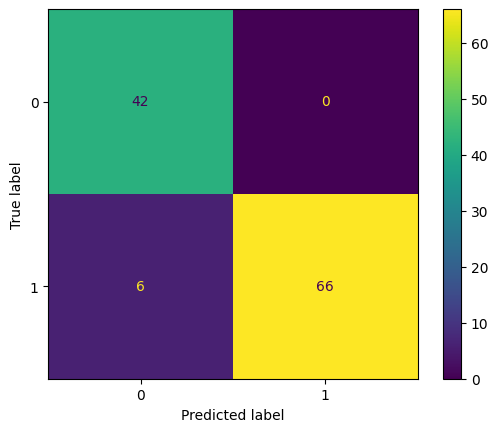

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay as CM

# create a confusion matrix
CM.from_predictions(Y_test, predict)

We can also extract the precision, recall and F1 score:

In [ ]:
from sklearn.metrics import precision_recall_fscore_support

# Calculate precision, recall, and F1-score
precision, recall, f1_score, _ = precision_recall_fscore_support(Y_test, predict, average='micro')

print(f"Micro-averaged Precision: {round(precision, 2)}")
print(f"Micro-averaged Recall: {round(recall, 2)}")
print(f"Micro-averaged F1-score: {round(f1_score, 2)}")
print("\n")

precision, recall, f1_score, _ = precision_recall_fscore_support(Y_test, predict, average='macro')

print(f"Macro-averaged Precision: {round(precision, 2)}")
print(f"Macro-averaged Recall: {round(recall, 2)}")
print(f"Macro-averaged F1-score: {round(f1_score, 2)}")

Micro-averaged Precision: 0.95
Micro-averaged Recall: 0.95
Micro-averaged F1-score: 0.95


Macro-averaged Precision: 0.94
Macro-averaged Recall: 0.96
Macro-averaged F1-score: 0.94


We can also see our tree:

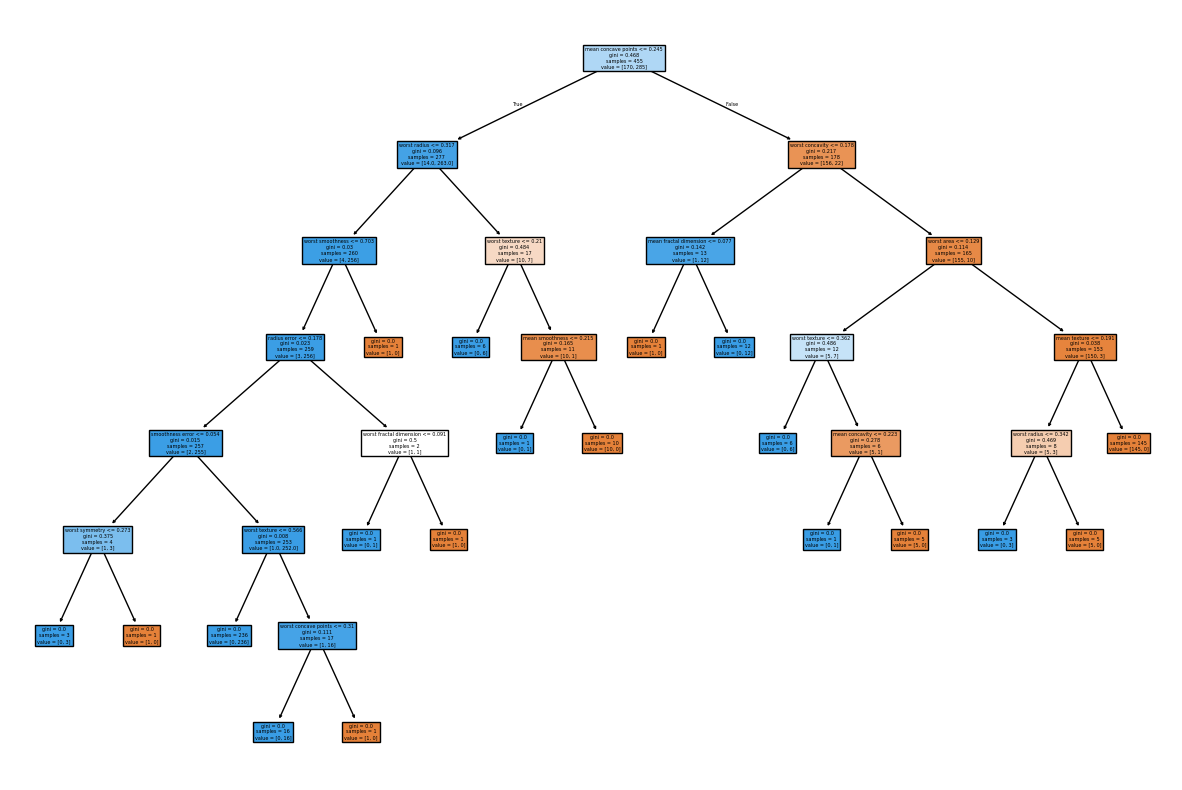

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 10))
plot_tree(DTC_model, filled=True, feature_names=X_train.columns)
plt.show()

We can see it has built a fairly large tree ... maybe it has overfit? Perhaps regularisation will help ...

We can search our hyperparameters and see what would be best:

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

# this is the list of parameters we will tune. Some are fixed values some are distributions
tuned_parameters = {
    'criterion': ['gini', 'entropy'],
    'max_depth': randint(3, 9),  # Draw from a uniform distribution between 3 and 15
    'min_samples_split': randint(3, 9),  # Draw from a uniform distribution between 2 and 10
    'max_features': ['sqrt', 'log2', None]
}

# we will tune against f1_macro (to find the best choice)
score = 'f1_macro' # arbitrary choice

print(f"Tuning hyperparameters for {score}")
print("\n")

# do the search using 5 folds/chunks
clf = RandomizedSearchCV(DTC(), tuned_parameters, cv=5, random_state=1984,
                         scoring= score, n_iter=20, refit=True)

# pass the data to fit/train
clf.fit(X_train, Y_train)

print("Best parameters set found on the training set:")
print(clf.best_params_)


Tuning hyperparameters for f1_macro


Best parameters set found on the training set:
{'criterion': 'gini', 'max_depth': 7, 'max_features': None, 'min_samples_split': 7}


Now we can train the model again, but using these hyperparameters:

In [ ]:
DTC_algo = DTC(**clf.best_params_) # get the best parameters from grid search
DTC_model = DTC_algo.fit(X_train, Y_train)

And now we can predict again:

In [ ]:
# predict the test data
predict = DTC_model.predict(X_test)

# seperate the first five predictions and the first five real values in Y_test
for i in range(5):
  print(f'Predicted: {round(predict[i],2)}')
  print(f'Real: {Y_test[i]}')
  print("\n")

print("\n")

print(f'Accuracy: {round(accuracy_score(Y_test, predict),2)}')

Predicted: 0
Real: 0


Predicted: 0
Real: 0


Predicted: 0
Real: 0


Predicted: 0
Real: 0


Predicted: 1
Real: 1




Accuracy: 0.94


Accuracy is better. However, we tuned for F1 macro ... maybe this will be better too:

Micro-averaged Precision: 0.94
Micro-averaged Recall: 0.94
Micro-averaged F1-score: 0.94


Macro-averaged Precision: 0.93
Macro-averaged Recall: 0.95
Macro-averaged F1-score: 0.94




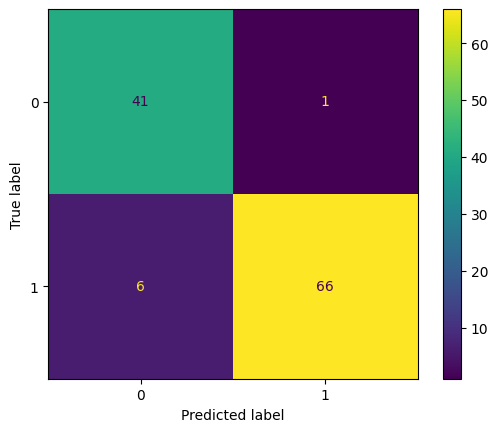

In [ ]:
# create a confusion matrix
CM.from_predictions(Y_test, predict)

# Calculate precision, recall, and F1-score
precision, recall, f1_score, _ = precision_recall_fscore_support(Y_test, predict, average='micro')

print(f"Micro-averaged Precision: {round(precision, 2)}")
print(f"Micro-averaged Recall: {round(recall, 2)}")
print(f"Micro-averaged F1-score: {round(f1_score, 2)}")
print("\n")

precision, recall, f1_score, _ = precision_recall_fscore_support(Y_test, predict, average='macro')

print(f"Macro-averaged Precision: {round(precision, 2)}")
print(f"Macro-averaged Recall: {round(recall, 2)}")
print(f"Macro-averaged F1-score: {round(f1_score, 2)}")
print("\n")

F1 score is 3 points higher! Let's also check the tree:

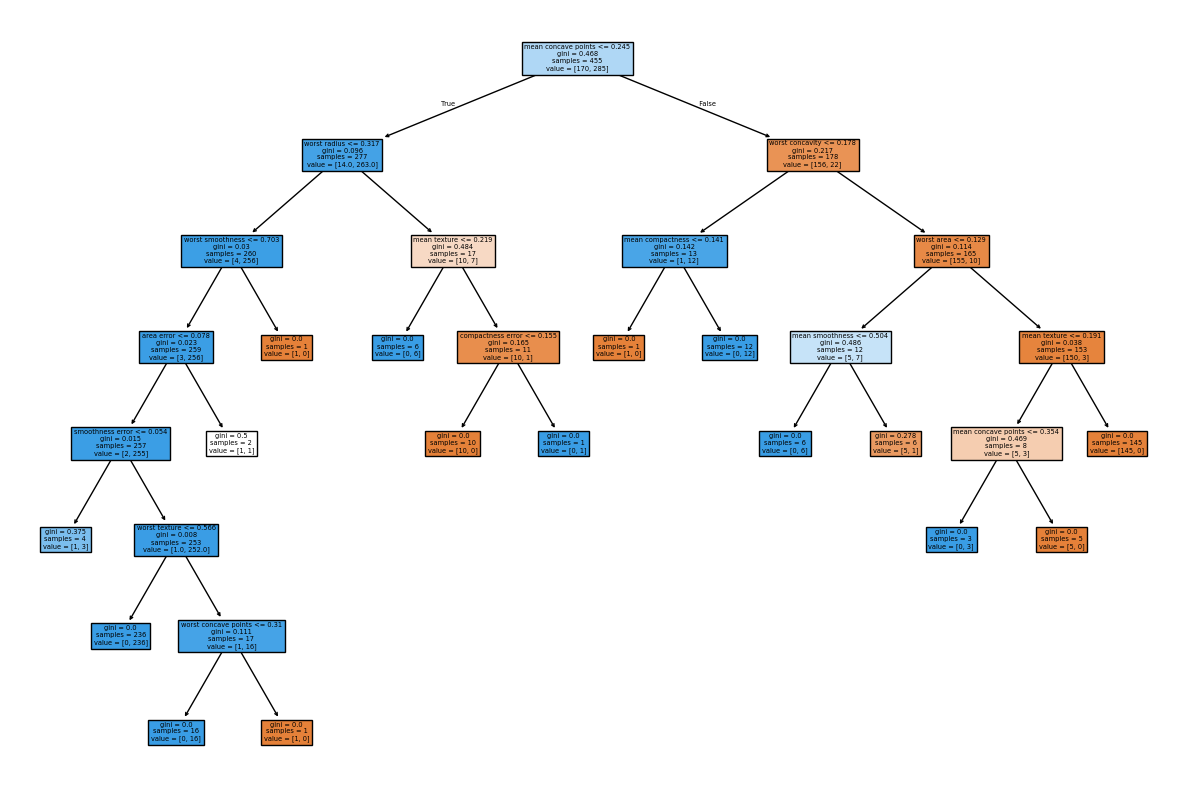

In [ ]:
plt.figure(figsize=(15, 10))
plot_tree(DTC_model, filled=True, feature_names=X_train.columns)
plt.show()

A much smaller tree so likely to be less prone to overfitting!

### TASK
Given that this is a medical domain, possibly a better metric to optimise against would be _recall_. Reoptimise the model according to _macro recall_ and evaluate the results.





Tuning hyperparameters for recall_macro

Best parameters set found:
{'criterion': 'entropy', 'max_depth': 3, 'max_features': 'sqrt', 'min_samples_split': 7}


Accuracy: 0.93


Micro-averaged Precision: 0.93
Micro-averaged Recall: 0.93
Micro-averaged F1-score: 0.93


Macro-averaged Precision: 0.93
Macro-averaged Recall: 0.91
Macro-averaged F1-score: 0.92


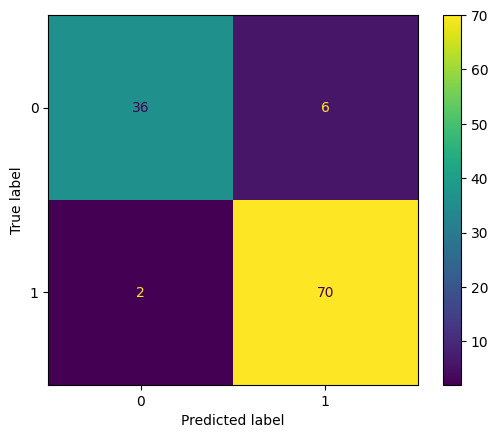

In [2]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint
from sklearn.tree import DecisionTreeClassifier as DTC
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay as CM, precision_recall_fscore_support
import matplotlib.pyplot as plt

# Define the hyperparameter grid
tuned_parameters = {
    'criterion': ['gini', 'entropy'],
    'max_depth': randint(3, 9),
    'min_samples_split': randint(3, 9),
    'max_features': ['sqrt', 'log2', None]
}

# Optimise against macro recall
score = 'recall_macro'
print(f"Tuning hyperparameters for {score}\n")

# Perform Randomized Search
clf = RandomizedSearchCV(DTC(random_state=1984), tuned_parameters, cv=5, random_state=1984,
                         scoring=score, n_iter=20, refit=True)

# Fit the search model
clf.fit(X_train, Y_train)

print("Best parameters set found:")
print(clf.best_params_)
print("\n")

# Instantiate and train the model using the best parameters found
DTC_algo = DTC(random_state=1984, **clf.best_params_)
DTC_model = DTC_algo.fit(X_train, Y_train)

# Predict the test data
predict = DTC_model.predict(X_test)

# Output performance metrics
print(f'Accuracy: {round(accuracy_score(Y_test, predict), 2)}')
print("\n")

# Calculate and print micro-averaged metrics
precision, recall, f1_score, _ = precision_recall_fscore_support(Y_test, predict, average='micro')
print(f"Micro-averaged Precision: {round(precision, 2)}")
print(f"Micro-averaged Recall: {round(recall, 2)}")
print(f"Micro-averaged F1-score: {round(f1_score, 2)}")
print("\n")

# Calculate and print macro-averaged metrics
precision, recall, f1_score, _ = precision_recall_fscore_support(Y_test, predict, average='macro')
print(f"Macro-averaged Precision: {round(precision, 2)}")
print(f"Macro-averaged Recall: {round(recall, 2)}")
print(f"Macro-averaged F1-score: {round(f1_score, 2)}")

# Plot the Confusion Matrix
CM.from_predictions(Y_test, predict)
plt.show()

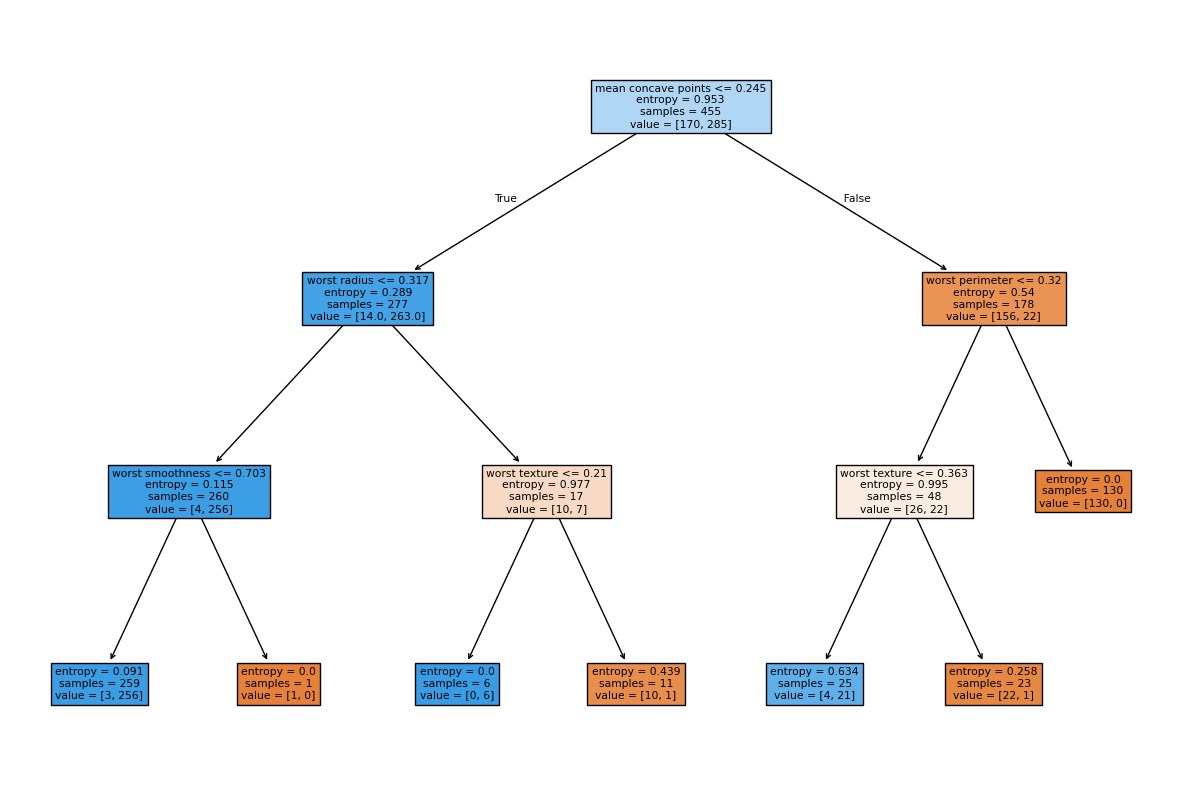

In [ ]:
plt.figure(figsize=(15, 10))
plot_tree(DTC_model, filled=True, feature_names=X_train.columns)
plt.show()

### Task: re-optimisation for recall – evaluation

Recall-macro (macro-averaged recall) calculates the unweighted mean of per-class recall. For a binary classification problem, this is equivalent to balanced accuracy. This metric treats both classes with equal importance, rewarding the model for catching benign cases as much as malignant ones.

However, in a clinical screening context, a false negative for Class 0 (malignant predicted as benign) is significantly more costly than a false positive. Missing a tumor has life-threatening consequences, whereas a false alarm merely results in further testing. Consequently, we will evaluate both the macro recall (as requested by the task) and the malignant-class recall (recall for Class 0) as a medically motivated alternative.

In [3]:
# Define parameters, custom scorer, helper search function, fit candidate models and run tie/depth checks
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint
from sklearn.tree import DecisionTreeClassifier as DTC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import make_scorer, recall_score, f1_score

# Safely ensure variables are initialized if the prior cells were not run
if 'X_train' not in locals() or 'Y_train' not in locals():
    data = load_breast_cancer()
    x_values = pd.DataFrame(data.data, columns=data.feature_names)
    scaler = MinMaxScaler()
    normal_data = scaler.fit_transform(x_values)
    x_values = pd.DataFrame(normal_data, columns=data.feature_names)
    y_value = np.ravel(pd.DataFrame(data.target, columns=['class']))
    X_train, X_test, Y_train, Y_test = train_test_split(x_values, y_value, test_size=0.2, random_state=1984, stratify=y_value)

# Define the uniform search space
search_space = {
    'criterion': ['gini', 'entropy'],
    'max_depth': randint(3, 9),
    'min_samples_split': randint(3, 9),
    'max_features': ['sqrt', 'log2', None]
}

# Create a scorer for malignant recall (Class 0)
malignant_recall = make_scorer(recall_score, pos_label=0)

# Helper function to run RandomizedSearchCV
def run_search(scoring):
    search = RandomizedSearchCV(
        estimator=DTC(random_state=1984),
        param_distributions=search_space,
        cv=5,
        n_iter=20,
        random_state=1984,
        scoring=scoring,
        refit=True
    )
    search.fit(X_train, Y_train)
    return search

# Run searches
search_f1_macro = run_search('f1_macro')
search_recall_macro = run_search('recall_macro')
search_malignant = run_search(malignant_recall)

# Build dictionary of fitted models
models = {
    'Baseline (default tree)': DTC(random_state=1984).fit(X_train, Y_train),
    'Tuned: f1_macro': search_f1_macro.best_estimator_,
    'Tuned: recall_macro (the task)': search_recall_macro.best_estimator_,
    'Tuned: malignant recall': search_malignant.best_estimator_,
    'Dummy: always malignant': DummyClassifier(strategy='constant', constant=0).fit(X_train, Y_train)
}

searches = {
    'Tuned: f1_macro': search_f1_macro,
    'Tuned: recall_macro (the task)': search_recall_macro,
    'Tuned: malignant recall': search_malignant
}

# Print metrics, tie checks, and depth checks for tuned models
for name, search in searches.items():
    best_est = search.best_estimator_
    print(f"=== {name} ===")
    print(f"Best Parameters: {search.best_params_}")
    print(f"Best CV Score: {round(search.best_score_, 4)}")
    print(f"Tree Depth: {best_est.get_depth()} | Leaves: {best_est.get_n_leaves()}")

    # Tie check
    cv_scores = search.cv_results_['mean_test_score']
    ties = np.sum((search.best_score_ - cv_scores) <= 0.005)
    print(f"Candidates within 0.005 of best CV score: {ties} / 20")

    # Boundary check
    if search.best_params_['max_depth'] == 3:
        print("Notice: Best max_depth is at the lower boundary (3) of the search range.")
    print("\n")

base = models['Baseline (default tree)']
print(f"Baseline tree -> Depth: {base.get_depth()} | Leaves: {base.get_n_leaves()}")

=== Tuned: f1_macro ===
Best Parameters: {'criterion': 'entropy', 'max_depth': 3, 'max_features': 'sqrt', 'min_samples_split': 7}
Best CV Score: 0.943
Tree Depth: 3 | Leaves: 7
Candidates within 0.005 of best CV score: 1 / 20
Notice: Best max_depth is at the lower boundary (3) of the search range.


=== Tuned: recall_macro (the task) ===
Best Parameters: {'criterion': 'entropy', 'max_depth': 3, 'max_features': 'sqrt', 'min_samples_split': 7}
Best CV Score: 0.9401
Tree Depth: 3 | Leaves: 7
Candidates within 0.005 of best CV score: 2 / 20
Notice: Best max_depth is at the lower boundary (3) of the search range.


=== Tuned: malignant recall ===
Best Parameters: {'criterion': 'entropy', 'max_depth': 6, 'max_features': 'sqrt', 'min_samples_split': 7}
Best CV Score: 0.9235
Tree Depth: 6 | Leaves: 18
Candidates within 0.005 of best CV score: 1 / 20


Baseline tree -> Depth: 7 | Leaves: 19


In [4]:
# Construct test set comparison dataframe
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

comparison_rows = []
for name, model in models.items():
    y_pred = model.predict(X_test)

    acc = accuracy_score(Y_test, y_pred)

    # Macro metrics
    prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(Y_test, y_pred, average='macro', zero_division=0)

    # Per-class metrics (Class 0 = malignant, Class 1 = benign)
    prec_class, rec_class, f1_class, _ = precision_recall_fscore_support(Y_test, y_pred, average=None, zero_division=0)

    # Confusion matrix extraction
    cm = confusion_matrix(Y_test, y_pred, labels=[0, 1])   # rows = true class, cols = predicted class
    missed_cancers = int(cm[0, 1])   # true malignant predicted benign (clinical false negative)
    false_alarms   = int(cm[1, 0])   # true benign predicted malignant (clinical false positive)

    # Sanity check
    assert missed_cancers == round((1 - rec_class[0]) * (Y_test == 0).sum()), f"Inconsistent FN for {name}"

    comparison_rows.append({
        'Model': name,
        'Accuracy': round(acc, 3),
        'Macro precision': round(prec_macro, 3),
        'Macro recall': round(rec_macro, 3),
        'Macro F1': round(f1_macro, 3),
        'Malignant recall': round(rec_class[0], 3),
        'Malignant precision': round(prec_class[0], 3),
        'Missed cancers (FN)': missed_cancers,
        'False alarms (FP)': false_alarms
    })

df_comparison = pd.DataFrame(comparison_rows)
display(df_comparison)

,Model,Accuracy,Macro precision,Macro recall,Macro F1,Malignant recall,Malignant precision,Missed cancers (FN),False alarms (FP)
0,Baseline (default tree),0.930,0.920,0.935,0.926,0.952,0.870,2,6
1,Tuned: f1_macro,0.930,0.934,0.915,0.923,0.857,0.947,6,2
2,Tuned: recall_macro (the task),0.930,0.934,0.915,0.923,0.857,0.947,6,2
3,Tuned: malignant recall,0.904,0.893,0.909,0.899,0.929,0.830,3,8
4,Dummy: always malignant,0.368,0.184,0.500,0.269,1.000,0.368,0,72


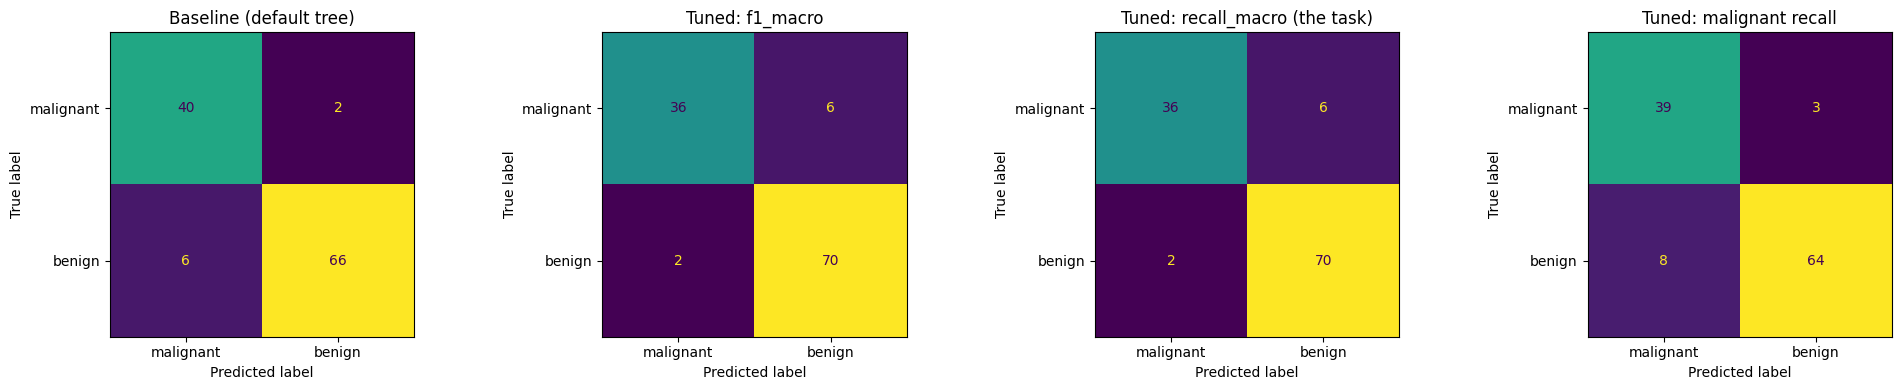

In [5]:
# Plot comparison confusion matrices
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay as CM

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
plt_models = ['Baseline (default tree)', 'Tuned: f1_macro', 'Tuned: recall_macro (the task)', 'Tuned: malignant recall']

for i, name in enumerate(plt_models):
    model = models[name]
    CM.from_predictions(
        Y_test,
        model.predict(X_test),
        display_labels=data.target_names,
        ax=axes[i],
        colorbar=False
    )
    axes[i].set_title(name)

plt.tight_layout()
plt.show()

=== Classification Report: Tuned: recall_macro ===
              precision    recall  f1-score   support

   malignant      0.947     0.857     0.900        42
      benign      0.921     0.972     0.946        72

    accuracy                          0.930       114
   macro avg      0.934     0.915     0.923       114
weighted avg      0.931     0.930     0.929       114



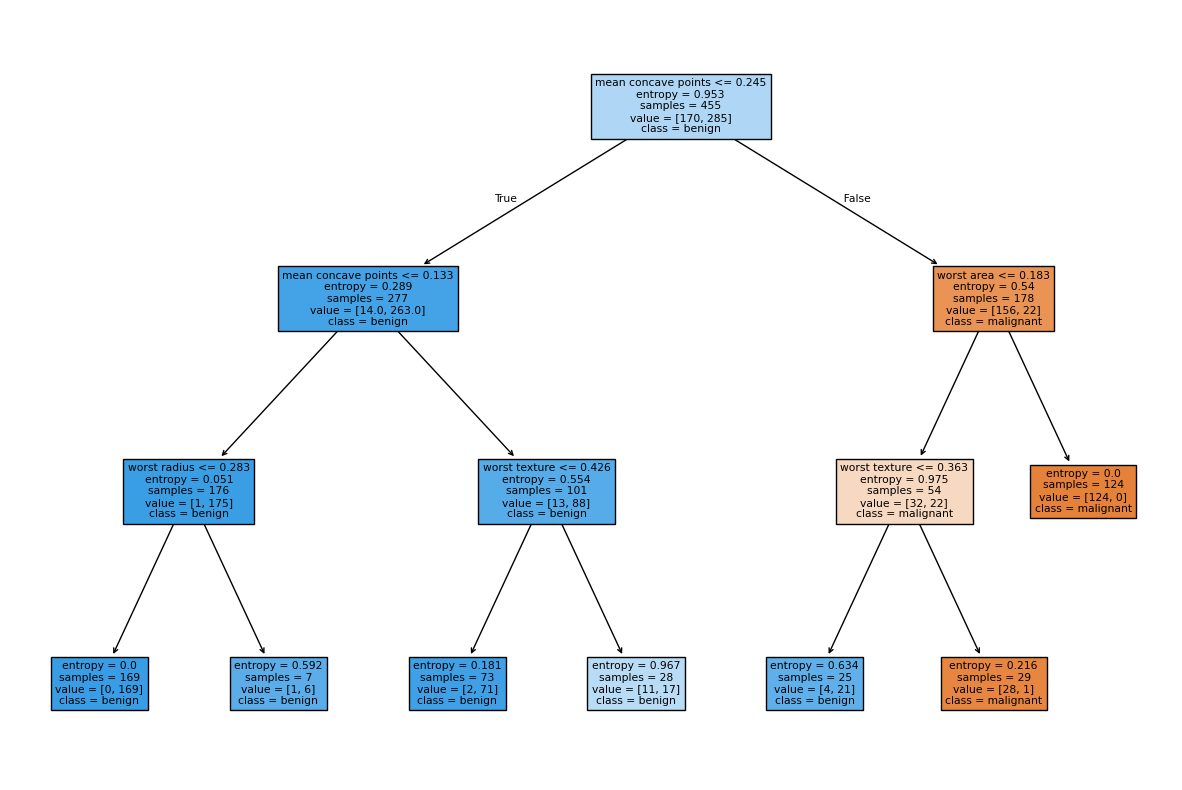

In [6]:
# Classification report and tree visualization for the recall_macro model
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
from sklearn.tree import plot_tree

task_model = models['Tuned: recall_macro (the task)']

print("=== Classification Report: Tuned: recall_macro ===")
print(classification_report(Y_test, task_model.predict(X_test), target_names=data.target_names, digits=3))

plt.figure(figsize=(15, 10))
plot_tree(
    task_model,
    filled=True,
    feature_names=X_train.columns,
    class_names=data.target_names,
    max_depth=None
)
plt.show()

### Evaluation & Commentary

1. **Selected hyperparameters.** The search tuned for `recall_macro` selected an entropy split criterion, `max_depth` = 3, `min_samples_split` = 7 and `max_features` = 'sqrt'. These are identical to the hyperparameters selected by the `f1_macro` search, so the two tuned estimators are the same model and, for that reason, give identical test results.

2. **Test-set performance of the task model.** On the test set, the `recall_macro` model achieves an accuracy of 0.930, a macro recall of 0.915 and a malignant-class recall of 0.857. This corresponds to **6 missed cancers (false negatives)** and **2 false alarms (false positives)**, consistent with the confusion matrix, the comparison table and the classification report.

3. **Why macro recall is not the right target.** `recall_macro` is the unweighted mean of the recall of both classes, which for a binary problem equals balanced accuracy. It therefore rewards catching benign cases as much as malignant ones and does not target the clinically costly error. As a result, the `recall_macro` model misses 6 cancers on the test set, more than the 3 missed by the model tuned directly on malignant recall and more than the 2 missed by the baseline tree.

4. **Clinical trade-off.** Tuning directly for malignant-class recall (class 0) reduces missed cancers to 3 (malignant recall 0.929) but raises false alarms to 8 and lowers accuracy to 0.904. In a screening context this trade is desirable: a missed tumour has life-threatening consequences, whereas a false alarm leads only to follow-up testing.

5. **Tree complexity.** The baseline tree is complex (depth 7, 19 leaves). The `f1_macro` and `recall_macro` models are regularised to depth 3 with 7 leaves, and the malignant-recall model lies in between (depth 6, 18 leaves). The smaller trees are less prone to overfitting, but they are not automatically better at the clinical objective, as the missed-cancer counts show.

6. **Caveats.**
   - The test set contains only 114 cases, so a single case is worth about 0.9 percentage points and differences of one or two cases should not be over-interpreted.
   - The tie check shows that only 1 of 20 candidates (`f1_macro`), 2 of 20 (`recall_macro`) and 1 of 20 (malignant recall) scored within 0.005 of the best cross-validation score, so the winning configurations are reasonably distinct, but the best cross-validation scores are close (0.943, 0.940 and 0.924 for their respective metrics).
   - The best `max_depth` of 3 for the `f1_macro` and `recall_macro` searches lies on the lower boundary of the search range (3–8), so a future search should extend the range downwards.
   - The untuned baseline missed only 2 cancers on the test set, but this is a single test-set observation that cross-validation did not select, so it is not used to choose a model.

7. **Sanity check with a trivial classifier.** The Dummy "always malignant" model reaches a perfect malignant recall of 1.0 with 0 missed cancers, yet it is clinically useless: it produces 72 false alarms (every benign case is flagged) and an accuracy of only 0.368. Recall must therefore always be reported together with precision or the false-alarm rate.

8. **Recommendation.** Based on 5-fold cross-validation targeting the primary clinical objective, the `Tuned: malignant recall` model is the recommended model: it optimises cross-validated malignant recall and misses only 3 cancers on the test set, at the cost of 8 false alarms. Optimising `recall_macro`, as the task literally asks, does not achieve this objective, because macro recall balances both classes instead of protecting the malignant class.
